# 雾密度网络：v1-nocolab 最简实验流程

更新于 2026-10-25，适用于恒源云等通用 GPU 服务器、本地及 Jupyter，先验版本为 `spatial_minmax_valid_boundary_v3`。

`准备代码 → 小张量检查 → 准备数据 → 固定实验配置和划分 → 训练 → 验证集看图 → 可选测试集评估 → 独立 Benchmark`

先按 [最简流程 Markdown](雾密度网络_最简实验流程.md) 获取 `v1-nocolab` 代码和安装依赖。选择服务器上的项目 Python 内核；本 notebook 直接使用现有源码，不自动下载或切换分支。

通过 `PROJECT_ROOT`、`DATASET_ROOT`、`OUTPUT_ROOT` 环境变量指定路径，也可修改下面对应变量。数据和实验目录应放在平台的持久化磁盘；默认实验目录是项目下的 `experiments/`，需自行确认项目所在磁盘的保存规则。

网络学习的是三先验生成的**相对评分伪标签**。拟合误差不能独立证明真实物理雾密度或下游检测效果。第 8 节提供已知透射率的独立 Benchmark。

## 1. 环境初始化

使用平台已安装 CUDA 版 PyTorch 的环境，并把 Jupyter 内核切换到同一个 Python。默认要求 CUDA 可用；本地仅做 CPU 检查时，可设 `REQUIRE_CUDA=False`。

项目根目录自动从当前目录向上查找；找不到时设置 `PROJECT_ROOT`。本节检查环境并打印分支、提交号和先验版本。更新源码或切换环境后先重启内核。

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys
from datetime import datetime, timezone

project_hint = Path(os.environ.get('PROJECT_ROOT', Path.cwd())).expanduser().resolve()
PROJECT_ROOT = next((p for p in (project_hint, *project_hint.parents)
                     if (p / 'configs/haze_density.yaml').is_file() and (p / 'src').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('请先获取 v1-nocolab 源码，并将 PROJECT_ROOT 指向项目根目录。')
BRANCH = 'v1-nocolab'
EXPECTED_PRIOR_VERSION = 'spatial_minmax_valid_boundary_v3'
REQUIRE_CUDA = True  # 本地 CPU 小规模检查可改为 False

def run_command(args, cwd=None):
    command = [str(arg) for arg in args]
    with subprocess.Popen(
        command, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, encoding='utf-8', bufsize=1,
        env={**os.environ, 'PYTHONUNBUFFERED': '1', 'PYTHONIOENCODING': 'utf-8'},
    ) as process:
        for line in process.stdout:
            print(line, end='', flush=True)
        returncode = process.wait()
    if returncode:
        raise subprocess.CalledProcessError(returncode, command)

os.chdir(PROJECT_ROOT)
if (PROJECT_ROOT / '.git').exists():
    CODE_BRANCH = subprocess.check_output(['git', 'branch', '--show-current'], text=True).strip()
    CODE_COMMIT = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip()
    if CODE_BRANCH != BRANCH:
        raise RuntimeError(f'当前分支 {CODE_BRANCH!r}，请在终端确认并使用 {BRANCH}，然后重启内核。')
else:
    CODE_BRANCH, CODE_COMMIT = 'uploaded source archive', 'unavailable'
    print('上传源码模式：无法核对 Git 分支；实验准备会保存源码文件哈希。')
run_command([sys.executable, 'scripts/utils/setup_environment.py',
             *(['--require-cuda'] if REQUIRE_CUDA else [])], cwd=PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch
import yaml
from src.models.haze_density.physical_prior import PRIOR_VERSION
if PRIOR_VERSION != EXPECTED_PRIOR_VERSION:
    raise RuntimeError(f'先验版本不符：{PRIOR_VERSION}，请确认使用当前源码。')
print(f'Branch: {CODE_BRANCH}\nCommit: {CODE_COMMIT}\nPrior: {PRIOR_VERSION}')
print(f'Python: {sys.executable}\nPyTorch: {torch.__version__}; CUDA: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

CrossModal-Defog-OVOD - 通用环境初始化


项目根目录：/mnt/CrossModal-Defog-OVOD


PyTorch 环境检查


✓ PyTorch version: 2.4.1+cu124


✓ CUDA available: True


...

✓ 环境初始化完成！


下一步:


  1. 运行 smoke test: python scripts/utils/smoke_test.py


  2. 按 docs/雾密度网络_最简实验流程.md 准备数据、持久化实验配置并训练


Branch: v1-nocolab
Commit: 2b549204e679ede504b25d623bd3199397d5814f
Prior: spatial_minmax_valid_boundary_v3
Python: /usr/bin/python
PyTorch: 2.4.1+cu124; CUDA: True
GPU: Tesla V100-SXM2-16GB


## 2. 训练前的小张量检查

每次更换代码或运行时后执行。这里只运行回归与前向、反向检查，不进行正式训练，也不需要 RSHaze+。检查失败时先解决报错；`skipped` 不代表通过。

In [2]:
checks = [
    ['scripts/utils/static_check.py'],
    ['-m', 'unittest', 'discover', '-s', 'scripts/test', '-p', 'test_review_regressions.py', '-v'],
    ['-m', 'unittest', 'discover', '-s', 'scripts/test', '-p', 'test_stage1_bugfixes.py', '-v'],
    ['scripts/test/test_physical_prior.py'],
    ['scripts/utils/smoke_test.py'],
]
for check in checks:
    run_command([sys.executable, *check], cwd=PROJECT_ROOT)

CrossModal-Defog-OVOD - 静态检查


目录结构检查


[OK] configs


[OK] docs


[OK] scripts


...

  2. 进入下一阶段：Encoder + 基础模块实现


torch=2.4.1+cu124, device=cuda, prior=spatial_minmax_valid_boundary_v3


[OK] (1, 3, 32, 48) -> (1, 1, 32, 48), loss=0.096352, backward/step complete


[OK] (2, 3, 48, 32) -> (2, 1, 48, 32), loss=0.096325, backward/step complete


[OK] Small-tensor smoke check passed


## 3. 数据准备

先把 RSHaze+ 上传、解压到服务器磁盘，修改 `DATASET_ROOT` 或设置同名环境变量。这里不自动下载、移动或复制整份数据。

最终结构为 `RSHaze+/RSHaze_G/train/synhazypng/` 等，同时有对应的 `cleanpng/`；另外两个子集为 `RSHaze_L`、`RSHaze_S`，每个子集都有官方 train/test。压缩包可能多包一层目录，请把路径指向直接包含三个子集的那一层。密度训练的 MSE 目标来自先验，不使用清晰图作为标签。

In [3]:
DATASET_ROOT = Path(os.environ.get('DATASET_ROOT', Path('/mnt/RSHaze+'))).expanduser().resolve()
SUBSETS = ('RSHaze_G', 'RSHaze_L', 'RSHaze_S')
for subset in SUBSETS:
    for official_split in ('train', 'test'):
        for folder in ('synhazypng', 'cleanpng'):
            directory = DATASET_ROOT / subset / official_split / folder
            if not directory.is_dir() or not any(directory.glob('*.png')):
                raise FileNotFoundError(f'目录缺失或没有 PNG：{directory}；请核对 DATASET_ROOT。')
    print(f'{subset}: 官方 train/test 目录检查通过')
print('数据目录：', DATASET_ROOT)

RSHaze_G: 官方 train/test 目录检查通过
RSHaze_L: 官方 train/test 目录检查通过
RSHaze_S: 官方 train/test 目录检查通过
数据目录： /mnt/RSHaze+


## 4. 固定实验配置和数据划分

修改 `OUTPUT_ROOT`，确认它位于平台的持久化磁盘；再设置 `RUN_NAME`、图像尺寸、batch size、worker 数和学习率。与终端流程共用 `prepare_experiment.py`，配置和划分不会被同名实验覆盖。新实验需换 `RUN_NAME`。

同一实验恢复时使用原路径、原设置和原 manifest；路径变化会触发配置不一致错误。划分检查不能排除内容重复或同场景泄漏。

In [4]:
from scripts.utils.prepare_experiment import prepare_experiment

OUTPUT_ROOT = Path(os.environ.get('OUTPUT_ROOT', PROJECT_ROOT / 'experiments')).expanduser().resolve()
RUN_NAME = 'spatial_v3_run01'
IMAGE_SIZE = 256
BATCH_SIZE = 4
NUM_WORKERS = 2  # 多进程或共享内存报错时用 0；更改已有实验设置需新 RUN_NAME
LEARNING_RATE = 1e-4

CONFIG_PATH = prepare_experiment(
    DATASET_ROOT, OUTPUT_ROOT, RUN_NAME, image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, lr=LEARNING_RATE,
)
RUN_DIR = CONFIG_PATH.parent
TRAIN_CONFIG = yaml.safe_load(CONFIG_PATH.read_text(encoding='utf-8'))
SPLIT_PATH = Path(TRAIN_CONFIG['split_file'])
CHECKPOINT_DIR = Path(TRAIN_CONFIG['checkpoint_dir'])
print(f'请确认持久化存储：{RUN_DIR}')


Split JSON 验证

检查 JSON schema...
train entries: 6417
val entries: 713
test entries: 930

Train unique keys: 6417
Val unique keys: 713
Test unique keys: 930

[OK] Train/Val: No overlap
[OK] Train/Test: No overlap
[OK] Val/Test: No overlap

内部重复检查:
[OK] Train: No internal duplicates
[OK] Val: No internal duplicates
[OK] Test: No internal duplicates

Subset 分布

Train:
  RSHaze_G: 900
  RSHaze_L: 4617
  RSHaze_S: 900

Val:
  RSHaze_G: 100
  RSHaze_L: 513
  RSHaze_S: 100

Test:
  RSHaze_G: 330
  RSHaze_L: 270
  RSHaze_S: 330

[OK] Split JSON 验证通过！
仅通过清单结构/原始路径检查；内容重复和同场景泄漏尚未核查。


train: 6417 images


val: 713 images


test: 930 images


Experiment: /mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01
Config: /mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/train_config.yaml
请确认持久化存储：/mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01


## 5. 训练与断点续训

第一次使用 `EPOCHS = 5`、`RESUME = False` 做短训练。正常完成后，将 `EPOCHS` 改为目标总轮数（例如 50），`RESUME = True`，从本实验的 `latest.pth` 继续。

`EPOCHS = 50` 表示累计训练到第 50 轮。恢复轮数必须大于已保存轮数。已有实验不能再次从头覆盖；新实验请更改第 4 节的 `RUN_NAME` 并重新执行第 4 节。

旧的无版本标记或 v2 权重不能续训成同一个 v3 实验。`best.pth` 用于查看验证集最优结果，`latest.pth` 用于恢复。日志逐轮保存在 实验目录的 `results/train_log.csv`。完整训练建议在 GPU 运行时执行。

In [5]:
EPOCHS = 50
RESUME = True

command = [
    sys.executable, '-u', 'scripts/train/train_haze_density.py',
    '--config', str(CONFIG_PATH), '--epochs', str(EPOCHS),
]
if RESUME:
    resume_path = CHECKPOINT_DIR / 'latest.pth'
    if not resume_path.is_file():
        raise FileNotFoundError(f'找不到续训权重：{resume_path}')
    saved = torch.load(resume_path, map_location='cpu', weights_only=True)
    if saved.get('config', {}).get('prior_version') != PRIOR_VERSION:
        raise ValueError('权重的先验版本不匹配，请为 v3 新开实验。')
    if EPOCHS <= saved['epoch']:
        raise ValueError(f'已训练 {saved["epoch"]} 轮，请将 EPOCHS 设为更大的目标总轮数。')
    command += ['--resume', str(resume_path)]
else:
    occupied = any((CHECKPOINT_DIR / name).exists() for name in ('best.pth', 'latest.pth'))
    if occupied or (Path(TRAIN_CONFIG['result_dir']) / 'train_log.csv').exists():
        raise FileExistsError('该实验已有权重或日志；请设 RESUME=True，或使用新的 RUN_NAME。')
run_command(command, cwd=PROJECT_ROOT)

BEST_CHECKPOINT = CHECKPOINT_DIR / 'best.pth'
if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(f'训练结束但没有找到 {BEST_CHECKPOINT}')
print(f'本次训练命令成功结束，最优权重：{BEST_CHECKPOINT}')

Stage 5D: HazeDensityNet Formal Training


Device: cuda


CUDA device: Tesla V100-SXM2-16GB


Creating model...


HazeDensityNet Model Summary


...

[OK] Target range: [0.1251, 0.9876]


[OK] Checkpoints saved (latest.pth, best.pth)


Result


[OK] Stage 5D Formal Training PASSED


本次训练命令成功结束，最优权重：/mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/checkpoints/best.pth


## 6. 加载 best.pth，在验证集上看图

本节可以单独重复运行。运行时重建后，先完成第 1—4 节以恢复路径，再直接运行本节，无需重新训练。

显示 `含雾图 | 先验伪标签 | 网络预测 | 绝对误差`，每子集最多 2 张。图像尺寸、模型和先验参数都从 checkpoint 读取；色标固定 0—1，每次保存到 实验目录的新时间目录。

这些图是按数据遍历顺序取样，用来检查训练结果；不能代替代表性抽样或独立正确性评测。日常调参使用验证集，测试集留到第 7 节。

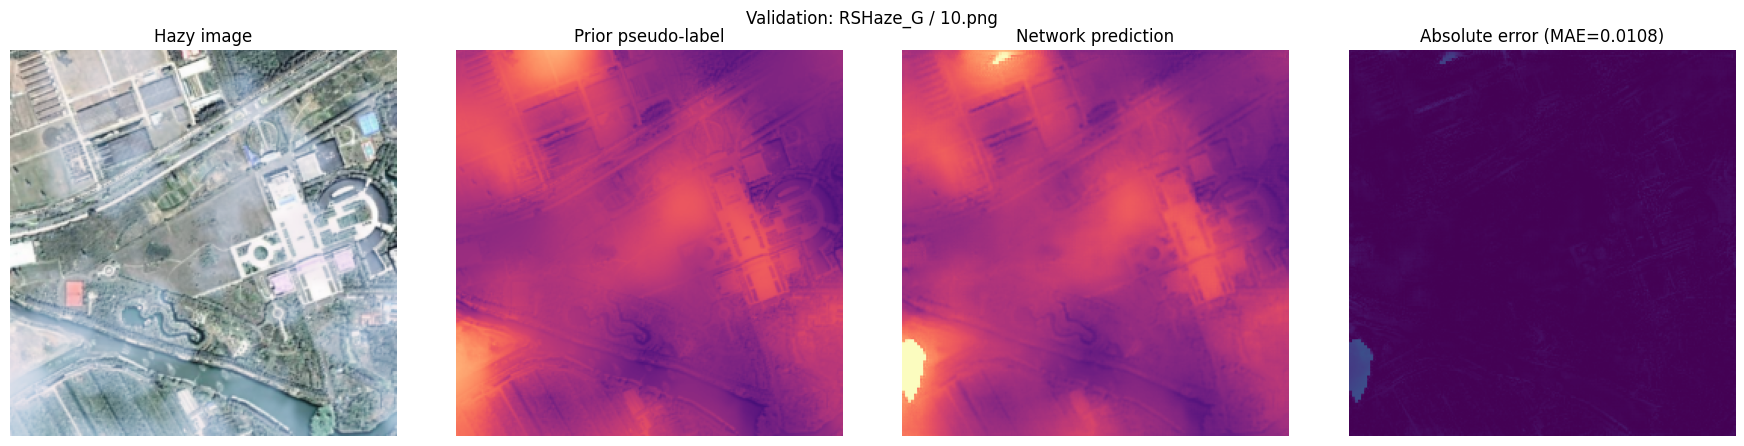

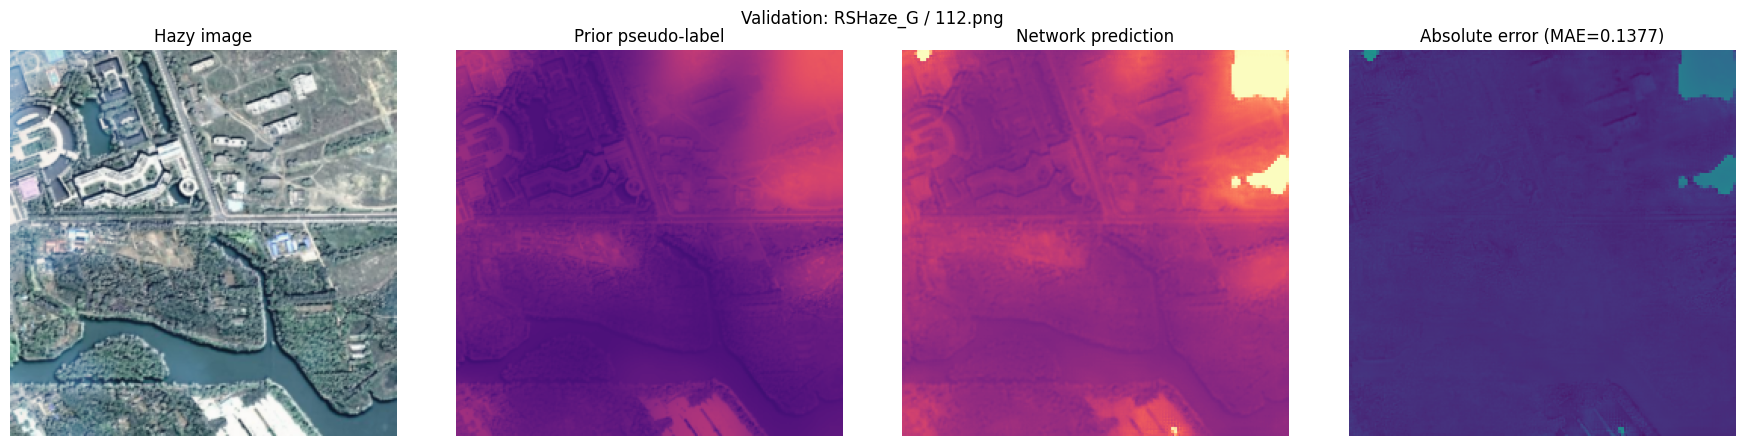

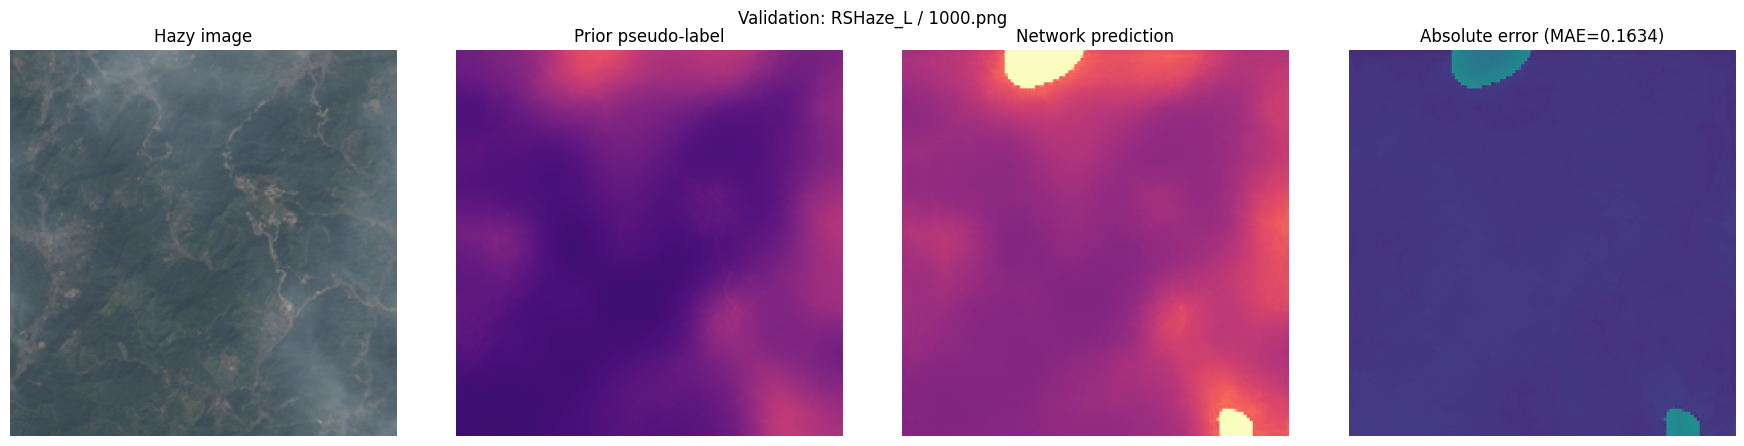

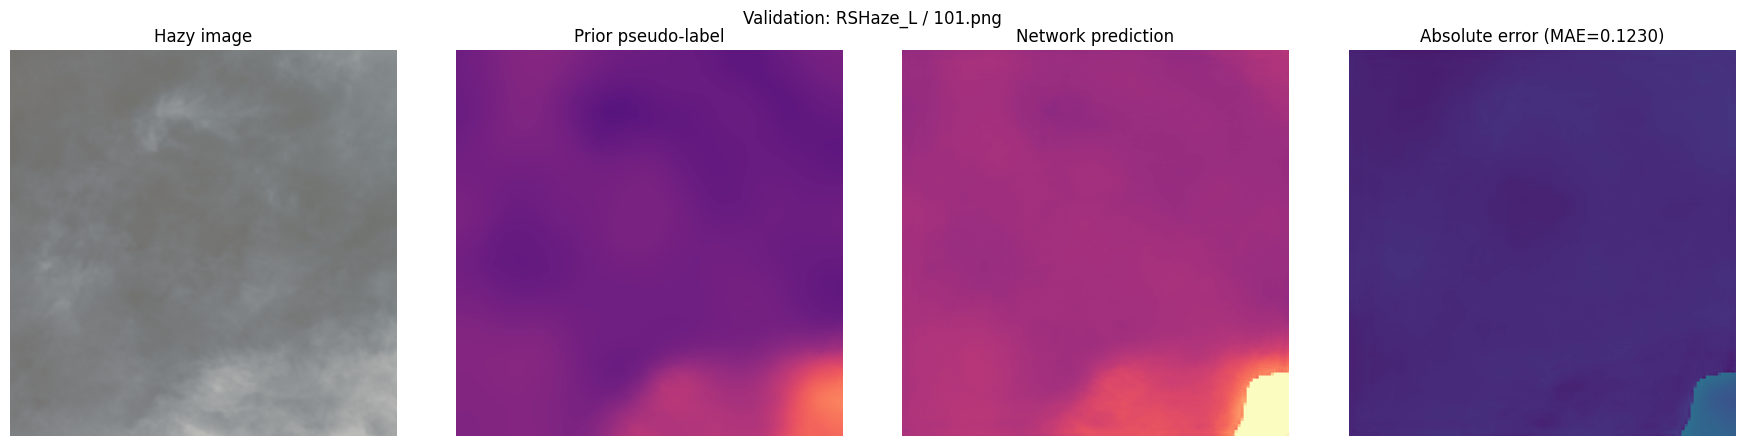

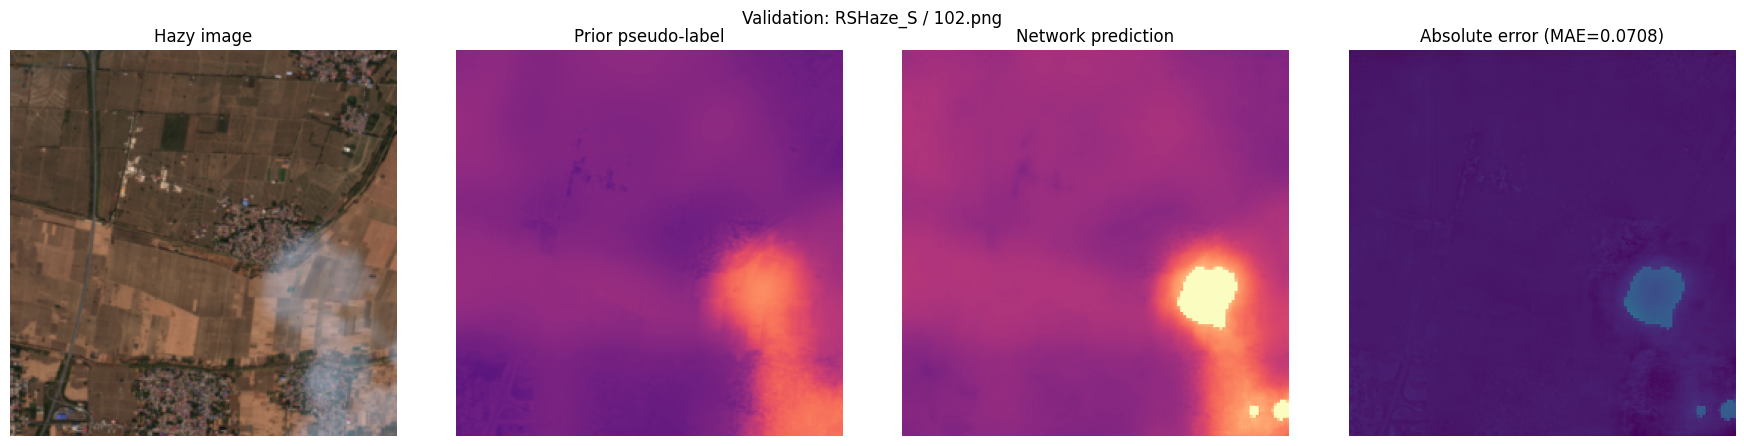

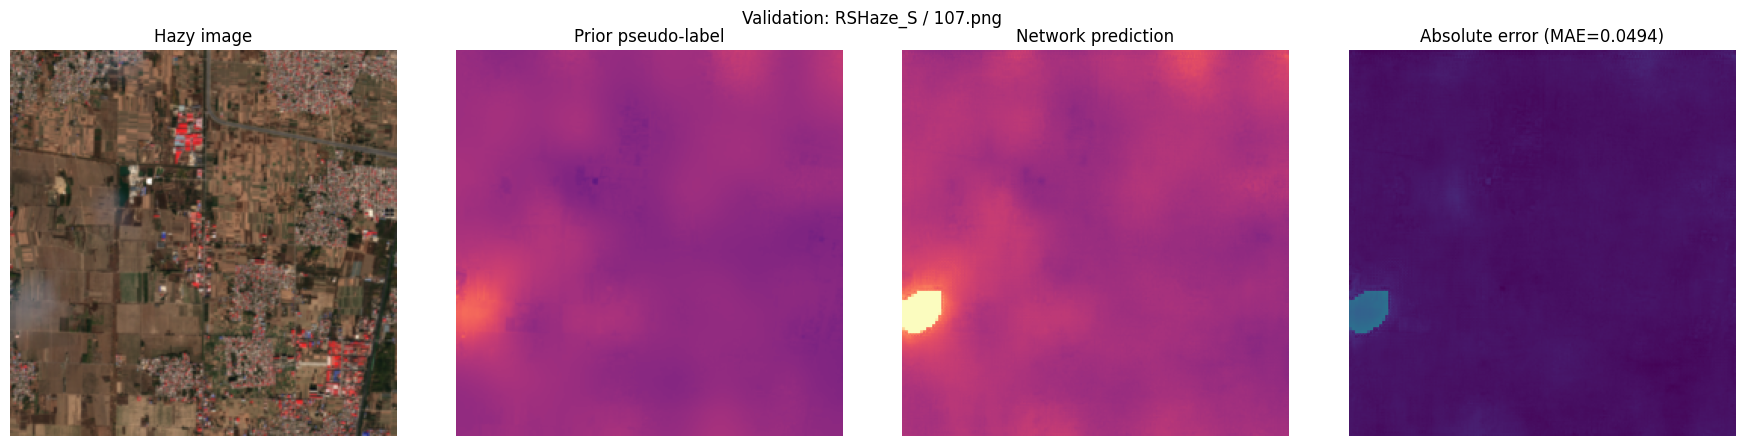

Checkpoint: /mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/checkpoints/best.pth
保存目录：/mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/validation_previews/20261025T134154_968685Z
每子集数量：{'RSHaze_G': 2, 'RSHaze_L': 2, 'RSHaze_S': 2}


In [6]:
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from src.data import build_rshazeplus_dataloader
from src.models.haze_density import HazeDensityNet
from src.models.haze_density.physical_prior import PhysicalPriorModule

BEST_CHECKPOINT = CHECKPOINT_DIR / 'best.pth'
if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(f'找不到 {BEST_CHECKPOINT}，请先完成本实验的训练。')
checkpoint = torch.load(BEST_CHECKPOINT, map_location='cpu', weights_only=True)
checkpoint_config = checkpoint['config']
if checkpoint_config.get('prior_version') != PRIOR_VERSION:
    raise ValueError('此 notebook 仅展示当前 v3 先验实验，请保留旧权重作历史资料。')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = HazeDensityNet(
    base_channels=checkpoint_config['base_channels'],
    use_sigmoid=checkpoint_config['use_sigmoid'],
).to(device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
physical_prior = PhysicalPriorModule(
    window_size=checkpoint_config['window_size'],
    guided_radius=checkpoint_config['guided_radius'],
    guided_eps=checkpoint_config['guided_eps'],
).to(device).eval()
preview_loader = build_rshazeplus_dataloader(
    root=checkpoint_config['dataset_root'], split='val',
    image_size=checkpoint_config['image_size'],
    batch_size=TRAIN_CONFIG['batch_size'], num_workers=0,
    pin_memory=(device.type == 'cuda'), split_file=checkpoint_config['split_file'],
)

stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
output_dir = RUN_DIR / 'validation_previews' / stamp
output_dir.mkdir(parents=True, exist_ok=False)
max_per_subset = 2
saved = defaultdict(int)
with torch.inference_mode():
    for batch in preview_loader:
        images = batch['image'].to(device)
        predictions = model(images)
        priors = physical_prior(images)
        if not torch.isfinite(predictions).all() or not torch.isfinite(priors).all():
            raise ValueError('预测或先验出现 NaN/Inf，请先排查，停止保存本次结果。')
        for i, subset in enumerate(batch['subset']):
            if saved[subset] >= max_per_subset:
                continue
            image = images[i].cpu().permute(1, 2, 0).numpy()
            prior = priors[i, 0].cpu().numpy()
            prediction = predictions[i, 0].cpu().numpy()
            error = np.abs(prior - prediction)
            fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
            axes[0].imshow(image)
            axes[0].set_title('Hazy image')
            axes[1].imshow(prior, cmap='magma', vmin=0, vmax=1)
            axes[1].set_title('Prior pseudo-label')
            axes[2].imshow(prediction, cmap='magma', vmin=0, vmax=1)
            axes[2].set_title('Network prediction')
            axes[3].imshow(error, cmap='viridis', vmin=0, vmax=1)
            axes[3].set_title(f'Absolute error (MAE={error.mean():.4f})')
            for axis in axes:
                axis.axis('off')
            fig.suptitle(f'Validation: {subset} / {batch["filename"][i]}')
            fig.tight_layout()
            output_path = output_dir / f'{subset}_{Path(batch["filename"][i]).stem}_density_result.png'
            fig.savefig(output_path, dpi=160, bbox_inches='tight')
            plt.show()
            plt.close(fig)
            saved[subset] += 1
        if all(saved[subset] >= max_per_subset for subset in SUBSETS):
            break

preview_info = {
    'checkpoint': str(BEST_CHECKPOINT), 'epoch': checkpoint['epoch'],
    'prior_version': PRIOR_VERSION, 'split': 'val',
    'image_size': checkpoint_config['image_size'],
    'prior_parameters': {key: checkpoint_config[key] for key in ('window_size', 'guided_radius', 'guided_eps')},
    'saved_per_subset': dict(saved),
}
(output_dir / 'preview_info.json').write_text(
    json.dumps(preview_info, ensure_ascii=False, indent=2) + '\n', encoding='utf-8',
)
print(f'Checkpoint: {BEST_CHECKPOINT}\n保存目录：{output_dir}\n每子集数量：{dict(saved)}')

## 7. 可选：方案确定后评估测试集

若只想检查训练是否正常，到第 6 节即可。最终方案确定后，再运行本节；不要反复用测试集挑参数。

评估使用 checkpoint 中的先验参数，并显式传递该实验的数据路径、划分和图像尺寸；每次使用新的空输出目录。MAE、RMSE、Pearson 衡量的是相对伪标签的拟合，不能单独作为物理雾密度准确性的证据。

In [7]:
BEST_CHECKPOINT = CHECKPOINT_DIR / 'best.pth'
checkpoint = torch.load(BEST_CHECKPOINT, map_location='cpu', weights_only=True)
evaluation_config = checkpoint['config']
if evaluation_config.get('prior_version') != PRIOR_VERSION:
    raise ValueError('权重先验版本不匹配，本流程不混用旧实验。')
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
evaluation_dir = RUN_DIR / 'test_evaluations' / stamp
run_command([
    sys.executable, '-u', 'scripts/evaluate/evaluate_haze_density.py',
    '--checkpoint', str(BEST_CHECKPOINT),
    '--dataset_root', evaluation_config['dataset_root'],
    '--split_file', evaluation_config['split_file'],
    '--image_size', str(evaluation_config['image_size']),
    '--batch_size', str(TRAIN_CONFIG['batch_size']),
    '--num_samples_per_subset', '16',
    '--output_dir', str(evaluation_dir),
], cwd=PROJECT_ROOT)
print(f'测试集报告与图像：{evaluation_dir}')

Stage 5E: HazeDensityNet Test Evaluation


Device: cuda


Loading checkpoint: /mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/checkpoints/best.pth


/mnt/CrossModal-Defog-OVOD/scripts/evaluate/evaluate_haze_density.py:134: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


  checkpoint = torch.load(args.checkpoint, map_location='cpu')


...

[PASS] Prediction range [0.0000, 1.0000] within [0, 1]


[PASS] All subsets completed: {'RSHaze_G', 'RSHaze_L', 'RSHaze_S'}


[PASS] Metrics saved to /mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/test_evaluations/20261025T134216_424091Z/test_metrics.txt


[ALL CHECKS PASSED]


测试集报告与图像：/mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/test_evaluations/20261025T134216_424091Z


## 8. 独立 Benchmark：雾密度判断是否可信

本节与第 7 节的“拟合伪标签”评估不同：使用官方 RSHaze_G **测试集清晰图**作为背景，按已知透射率合成雾，分别检验雾强度排序、空间分布、无雾响应，并计时。可以在第 1、3、4 节后独立运行，不必重新训练；如果已有本实验当前先验版本的 `best.pth`，会加入学生网络。**只在方案确定后查看测试结果，不要据此反复调训练超参数。**

优先复用第 3 节的数据，核对四张官方清晰图的 SHA256；缺少匹配图时，可显式开启从官方 ZIP 按字节范围获取小样本，硬限制 24 MiB。四个地物 ROI 属于一个保守地理组，结果不能证明跨地区泛化。实验会跑最小闭环、128 样本扩展评测和 CPU/GPU 性能；缺少 GPU 或合格权重会明确标为 NOT RUN/NOT EVALUATED。结果、真值、图和日志保存在持久化实验目录的 `benchmarks/` 新目录。

下面第一个代码单元只解包经过校验的评测代码，不会替换训练中的模块。第二个单元运行评测，第三个单元读取结果。完整定义见 [Benchmark 使用说明](guides/haze_density_benchmark.md)。


In [8]:
# 选择已安装依赖的 Python / Jupyter 内核；代码包可解压到系统临时目录。
import base64, hashlib, io, pathlib, tempfile, zipfile, importlib.util
missing = [m for m in ['torch', 'numpy', 'PIL', 'yaml', 'matplotlib', 'scipy'] if importlib.util.find_spec(m) is None]
if missing:
    raise RuntimeError('NOT RUN: 缺少依赖 ' + ', '.join(missing) + '；请先安装项目 requirements.txt。')
payload = base64.b64decode('...')
assert hashlib.sha256(payload).hexdigest() == '221dfd20aeb83f26c2dc44561669898910ebe176a2fd83444654e898631175ab'
PROJECT = pathlib.Path(tempfile.mkdtemp(prefix='stage2_haze_')).resolve()
with zipfile.ZipFile(io.BytesIO(payload)) as archive:
    for entry in archive.infolist():
        target = (PROJECT / entry.filename).resolve()
        if not target.is_relative_to(PROJECT):
            raise ValueError('Invalid bundle member')
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(entry))
print('项目代码已解包：', PROJECT)

BENCHMARK_ROOT = PROJECT
print("独立评测代码：", BENCHMARK_ROOT)


项目代码已解包： /tmp/stage2_haze_cav6tj_2
独立评测代码： /tmp/stage2_haze_cav6tj_2


In [9]:
# 需要第 1、3、4 节提供的 PROJECT_ROOT、DATASET_ROOT、RUN_DIR 与 PRIOR_VERSION。
if not DATASET_ROOT.is_dir() or not RUN_DIR.is_dir():
    raise RuntimeError('请先完成第 3、4 节的数据和实验目录准备。')
# 在新评测进程启动前配置 CUDA 确定性矩阵运算。
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
ALLOW_SMALL_SAMPLE_DOWNLOAD = False  # 缺少官方小样本且允许联网时改为 True；硬上限 24 MiB。
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
BENCHMARK_OUTPUT = RUN_DIR / 'benchmarks' / stamp
benchmark_command = [
    sys.executable, '-u', str(BENCHMARK_ROOT / 'scripts/benchmark/run_benchmark.py'),
    '--data-root', str(DATASET_ROOT), '--output', str(BENCHMARK_OUTPUT),
]
if ALLOW_SMALL_SAMPLE_DOWNLOAD:
    benchmark_command.append('--fetch-small-sample')
candidate = CHECKPOINT_DIR / 'best.pth'
if candidate.is_file():
    saved = torch.load(candidate, map_location='cpu', weights_only=True)
    if saved.get('config', {}).get('prior_version') == PRIOR_VERSION and saved.get('epoch', 0) >= 1:
        benchmark_command += ['--checkpoint', str(candidate)]
        print('学生网络将使用本实验当前版本权重：', candidate)
    else:
        print('权重缺少当前先验版本或训练轮次，学生正确性将标记 NOT EVALUATED：', candidate)
else:
    print('未找到本实验权重；DCP/三先验仍可评测，学生正确性 NOT EVALUATED。')
print('独立评测结果将保存在：', BENCHMARK_OUTPUT)
run_command(benchmark_command, cwd=BENCHMARK_ROOT)


学生网络将使用本实验当前版本权重： /mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/checkpoints/best.pth
独立评测结果将保存在： /mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/benchmarks/20261025T134327_753304Z



RUN: unit_tests


..................dcp: 1/2 cases


prior: 1/2 cases


......[WARN] Split file /tmp/tmpa3oh3zy1/split.json not found, using default split


...

PASS performance: dcp cuda 512


PASS performance: prior cuda 512


PASS performance: student cuda 512


PASS: command completed; consult method-level NOT RUN / N/A statuses


Completed. Read method-level statuses; PASS does not mean the algorithm is accurate. Results: /mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/benchmarks/20261025T134327_753304Z


各阶段执行状态： [{'stage': 'unit_tests', 'status': 'PASS', 'exit_code': 0}, {'stage': 'minimal_generate', 'status': 'PASS', 'exit_code': 0}, {'stage': 'minimal_evaluate', 'status': 'PASS', 'exit_code': 0}, {'stage': 'minimal_report', 'status': 'PASS', 'exit_code': 0}, {'stage': 'full_generate', 'status': 'PASS', 'exit_code': 0}, {'stage': 'full_evaluate', 'status': 'PASS', 'exit_code': 0}, {'stage': 'full_report', 'status': 'PASS', 'exit_code': 0}, {'stage': 'performance', 'status': 'PASS', 'exit_code': 0}]


# 独立雾响应评测报告

执行状态：PASS；数据性质：real_clear_remote_sensing；划分：test。

PASS 表示评测实现成功运行，不代表算法已经通过科学有效性验证。缺少预注册验收阈值时，以下指标均为描述性结果。

## 方法可用性

| 方法 | 状态 | 说明 |
|---|---|---|
| dcp | PASS | 独立真值评测已执行 |
| prior | PASS | 独立真值评测已执行 |
| student | PASS | 独立真值评测已执行 |

## 场景宏平均

| 方法 | 地物 | 场景组数 | 排序准确率 | 平局率 | Spearman | 单调性违反率 | 无雾响应 | 空间区域 Spearman |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| dcp | ALL | 1.0000 | 1.0000 | 0.0000 | 1.0000 | 0.0000 | 0.1349 | 0.9593 |
| dcp | bare_soil | 1.0000 | 1.0000 | 0.0000 | 1.0000 | 0.0000 | 0.2845 | 0.9499 |
| dcp | urban | 1.0000 | 1.0000 | 0.0000 | 1.0000 | 0.0000 | 0.1802 | 0.9379 |
| dcp | vegetation | 1.0000 | 1.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0194 | 0.9794 |
| dcp | water | 1.0000 | 1.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0554 | 0.9700 |
| prior | ALL | 1.0000 | 0.2188 | 0.0000 | -0.5562 | 0.7812 | 0.3980 | 0.9558 |
| prior | bare_soil | 1.0000 | 0.0000 | 0.0000 | -1.0000 | 1.0000 | 0.5431 | 0.9363 |
| prior | urban | 1.0000 | 0.0000 | 0.0000 | -1.0000 | 1.0000 | 0.4707 | 0.9323 |
| prior | vegetation | 1.0000 | 0.5000 | 0.0000 | 0.0000 | 0.5000 | 0.2982 | 0.9789 |
| prior | water | 1.0000 | 0.3750 | 0.0000 | -0.2250 | 0.6250 | 0.2799 | 0.9757 |
| student | ALL | 1.0000 | 0.7750 | 0.0000 | 0.6062 | 0.2812 | 0.4856 | 0.9556 |
| student | bare_soil | 1.0000 | 0.4250 | 0.0000 | -0.1000 | 0.6250 | 0.5086 | 0.9409 |
| student | urban | 1.0000 | 0.9750 | 0.0000 | 0.9750 | 0.0625 | 0.4833 | 0.9276 |
| student | vegetation | 1.0000 | 0.8250 | 0.0000 | 0.7250 | 0.2500 | 0.4735 | 0.9791 |
| student | water | 1.0000 | 0.8750 | 0.0000 | 0.8250 | 0.1875 | 0.4770 | 0.9747 |

各场景内先平均、再对场景组宏平均。详见 `condition_strata.csv` 的地物×大气光×亮度分层及 `results.json` 的有效场景数。未知地物不冒充城市/植被/水体/裸地。

无雾响应阈值仅为各方法内部诊断，不是跨方法校准过的 FPR；预测与透射率没有直接计算物理 MAE。常量真值的空间相关为 N/A，常量预测的相关也为 N/A。

## 典型排序失败候选

- prior / G_test_1053，A=[0.75, 0.8, 0.9]，brightness=1.0：accuracy=0.000，ties=0.000，strong−clear=-0.0448。可检验的解释包括反射率/颜色混淆与逐图归一化丢失幅值；当前实验未做因果归因。
- prior / G_test_1053，A=[0.75, 0.8, 0.9]，brightness=0.7：accuracy=0.000，ties=0.000，strong−clear=-0.0436。可检验的解释包括反射率/颜色混淆与逐图归一化丢失幅值；当前实验未做因果归因。
- prior / G_test_1072，A=[0.75, 0.8, 0.9]，brightness=1.0：accuracy=0.000，ties=0.000，strong−clear=-0.0520。可检验的解释包括反射率/颜色混淆与逐图归一化丢失幅值；当前实验未做因果归因。
- prior / G_test_1072，A=[0.75, 0.8, 0.9]，brightness=0.7：accuracy=0.000，ties=0.000，strong−clear=-0.0489。可检验的解释包括反射率/颜色混淆与逐图归一化丢失幅值；当前实验未做因果归因。
- prior / G_test_1126，A=[1.0, 1.0, 1.0]，brightness=1.0：accuracy=0.000，ties=0.000，strong−clear=-0.1165。可检验的解释包括反射率/颜色混淆与逐图归一化丢失幅值；当前实验未做因果归因。
- prior / G_test_1126，A=[1.0, 1.0, 1.0]，brightness=0.7：accuracy=0.000，ties=0.000，strong−clear=-0.1134。可检验的解释包括反射率/颜色混淆与逐图归一化丢失幅值；当前实验未做因果归因。
- prior / G_test_1126，A=[0.75, 0.8, 0.9]，brightness=1.0：accuracy=0.000，ties=0.000，strong−clear=-0.1889。可检验的解释包括反射率/颜色混淆与逐图归一化丢失幅值；当前实验未做因果归因。
- prior / G_test_1126，A=[0.75, 0.8, 0.9]，brightness=0.7：accuracy=0.000，ties=0.000，strong−clear=-0.1960。可检验的解释包括反射率/颜色混淆与逐图归一化丢失幅值；当前实验未做因果归因。

## 空间响应失败候选

- prior / G_test_1328__a1_b0__blob：区域 Spearman=0.8147，重雾−轻雾响应差=0.3348。负相关/负差表示该样例上与已知退化方向冲突；具体原因还需受控消融。
- student / G_test_1328__a1_b0__blob：区域 Spearman=0.8176，重雾−轻雾响应差=0.2960。负相关/负差表示该样例上与已知退化方向冲突；具体原因还需受控消融。
- dcp / G_test_1328__a1_b0__blob：区域 Spearman=0.8353，重雾−轻雾响应差=0.2712。负相关/负差表示该样例上与已知退化方向冲突；具体原因还需受控消融。
- student / G_test_1328__a0_b0__blob：区域 Spearman=0.8353，重雾−轻雾响应差=0.3325。负相关/负差表示该样例上与已知退化方向冲突；具体原因还需受控消融。
- student / G_test_1328__a1_b1__blob：区域 Spearman=0.8353，重雾−轻雾响应差=0.3229。负相关/负差表示该样例上与已知退化方向冲突；具体原因还需受控消融。
- prior / G_test_1328__a0_b0__blob：区域 Spearman=0.8618，重雾−轻雾响应差=0.3740。负相关/负差表示该样例上与已知退化方向冲突；具体原因还需受控消融。
- prior / G_test_1126__a1_b0__blob：区域 Spearman=0.8647，重雾−轻雾响应差=0.3272。负相关/负差表示该样例上与已知退化方向冲突；具体原因还需受控消融。
- prior / G_test_1126__a1_b1__blob：区域 Spearman=0.8647，重雾−轻雾响应差=0.3321。负相关/负差表示该样例上与已知退化方向冲突；具体原因还需受控消融。



# 雾密度模块工程性能

执行状态：PASS。计时精度 FP32，batch=1；预热和重复次数见 JSON。

端到端包含内存 PNG 解码、RGB 转换/缩放、张量转换、传输、前向和回传，不含磁盘、网络、模型初始化。吞吐是该串行 batch=1 协议下的实测吞吐。

| 方法 | 设备 | 尺寸 | 范围 | 状态 | P50 ms | P95 ms | images/s | 参数量 |
|---|---|---:|---|---|---:|---:|---:|---:|
| dcp | cpu | 256 | forward | PASS | 67.725 | 82.106 | 14.247 | 0 |
| dcp | cpu | 256 | end_to_end | PASS | 70.011 | 71.167 | 14.286 | 0 |
| prior | cpu | 256 | forward | PASS | 497.313 | 502.974 | 2.007 | 0 |
| prior | cpu | 256 | end_to_end | PASS | 497.849 | 511.264 | 2.000 | 0 |
| student | cpu | 256 | forward | PASS | 377.514 | 388.372 | 2.651 | 864752 |
| student | cpu | 256 | end_to_end | PASS | 379.693 | 385.871 | 2.640 | 864752 |
| dcp | cpu | 512 | forward | PASS | 268.547 | 269.625 | 3.726 | 0 |
| dcp | cpu | 512 | end_to_end | PASS | 282.485 | 308.906 | 3.474 | 0 |
| prior | cpu | 512 | forward | PASS | 2029.331 | 2055.051 | 0.494 | 0 |
| prior | cpu | 512 | end_to_end | PASS | 2048.723 | 2078.331 | 0.488 | 0 |
| student | cpu | 512 | forward | PASS | 1735.502 | 1791.252 | 0.578 | 864752 |
| student | cpu | 512 | end_to_end | PASS | 1732.157 | 1808.618 | 0.574 | 864752 |
| dcp | cuda | 256 | forward | PASS | 0.153 | 0.167 | 6461.452 | 0 |
| dcp | cuda | 256 | end_to_end | PASS | 3.541 | 6.337 | 238.736 | 0 |
| prior | cuda | 256 | forward | PASS | 3.314 | 5.800 | 263.860 | 0 |
| prior | cuda | 256 | end_to_end | PASS | 6.297 | 6.417 | 156.740 | 0 |
| student | cuda | 256 | forward | PASS | 9.411 | 9.650 | 105.086 | 864752 |
| student | cuda | 256 | end_to_end | PASS | 12.842 | 13.081 | 77.499 | 864752 |
| dcp | cuda | 512 | forward | PASS | 0.323 | 0.453 | 2890.565 | 0 |
| dcp | cuda | 512 | end_to_end | PASS | 8.375 | 8.667 | 117.282 | 0 |
| prior | cuda | 512 | forward | PASS | 2.845 | 3.597 | 326.290 | 0 |
| prior | cuda | 512 | end_to_end | PASS | 10.653 | 10.794 | 93.972 | 0 |
| student | cuda | 512 | forward | PASS | 26.385 | 26.567 | 37.905 | 864752 |
| student | cuda | 512 | end_to_end | PASS | 34.733 | 35.393 | 28.648 | 864752 |

显存与原始逐次延迟见 `performance.json`。CPU 显存为 N/A；CUDA 缺失为 NOT RUN。MACs 仅统计 Conv/Linear，不能冒充完整 FLOPs。

`student_architecture_only` 使用未训练的相同网络，仅反映结构计算成本，其正确性仍是 NOT EVALUATED。设备不同的数字不能直接证明算法优劣。


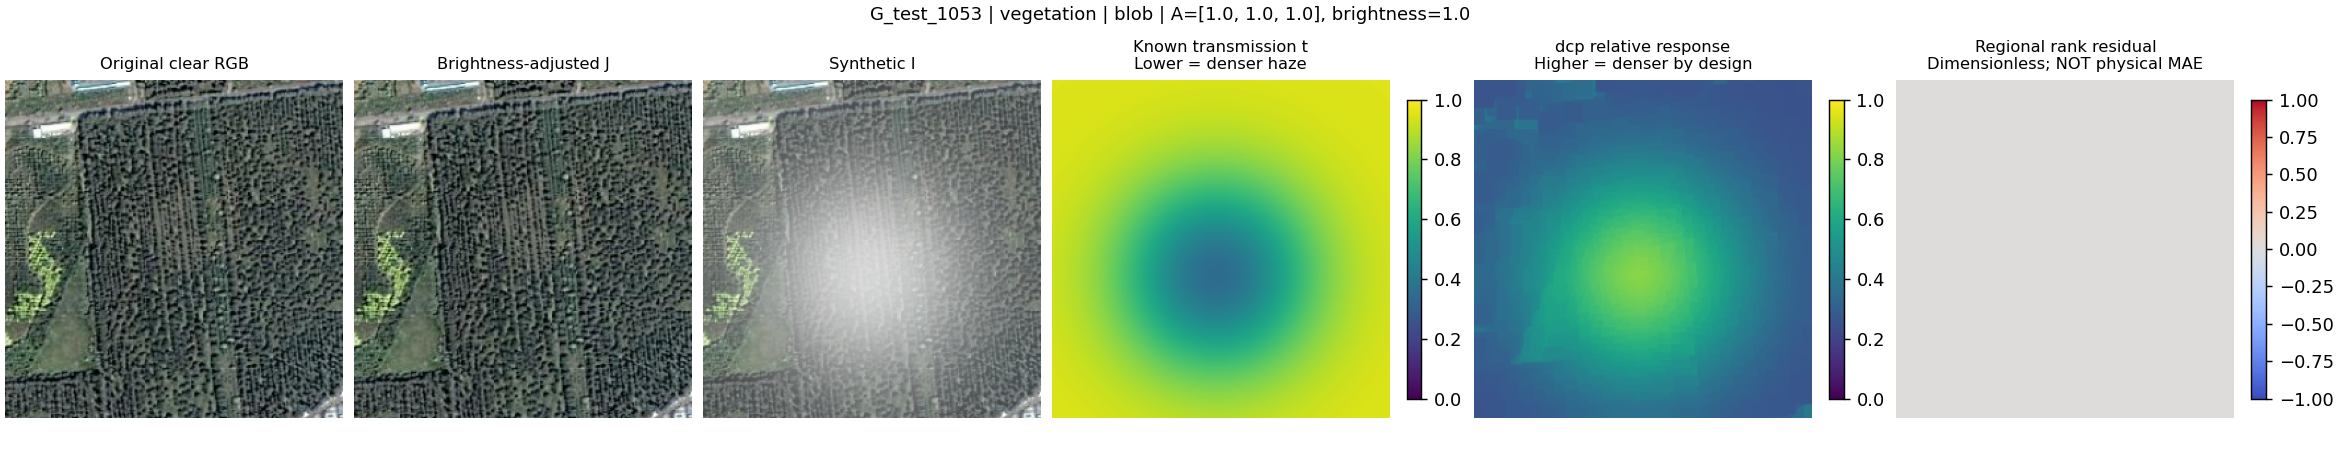

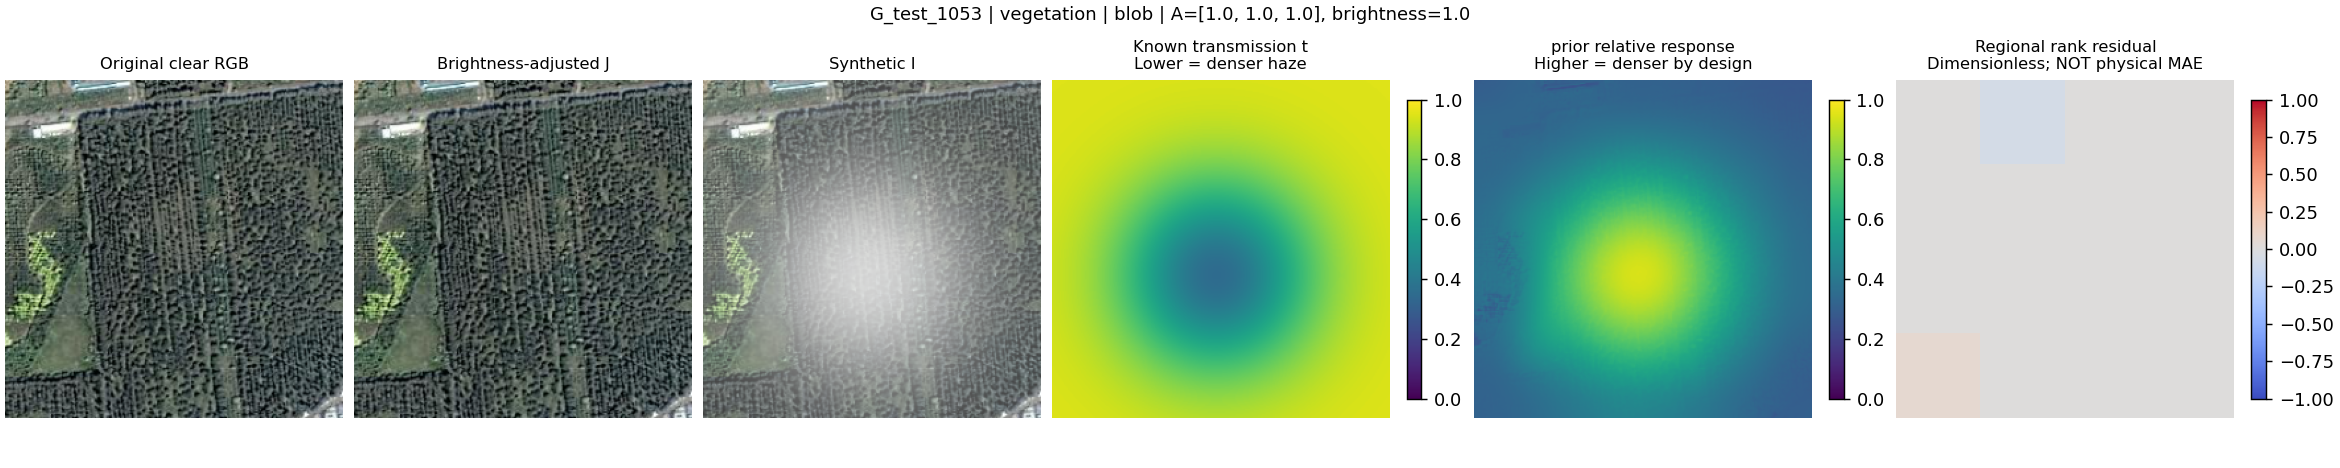

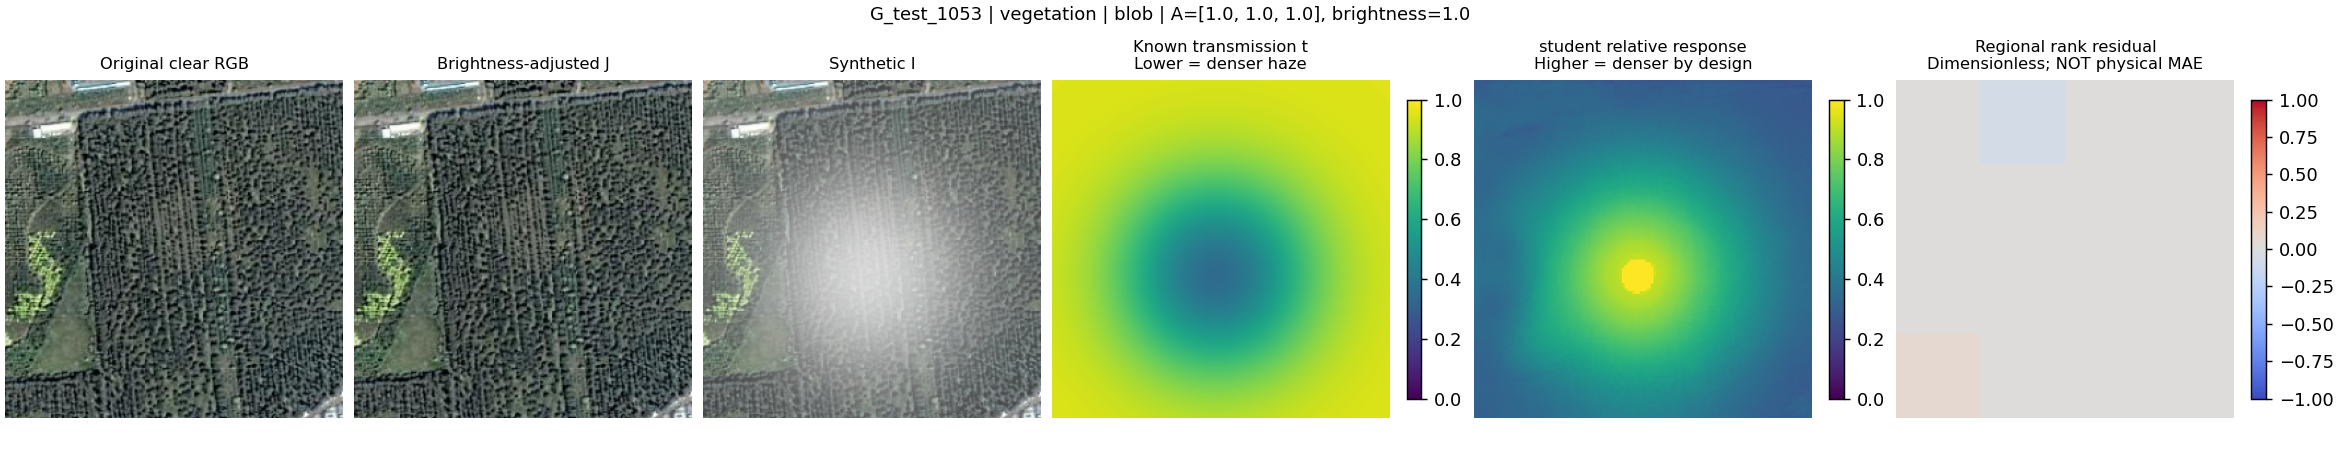

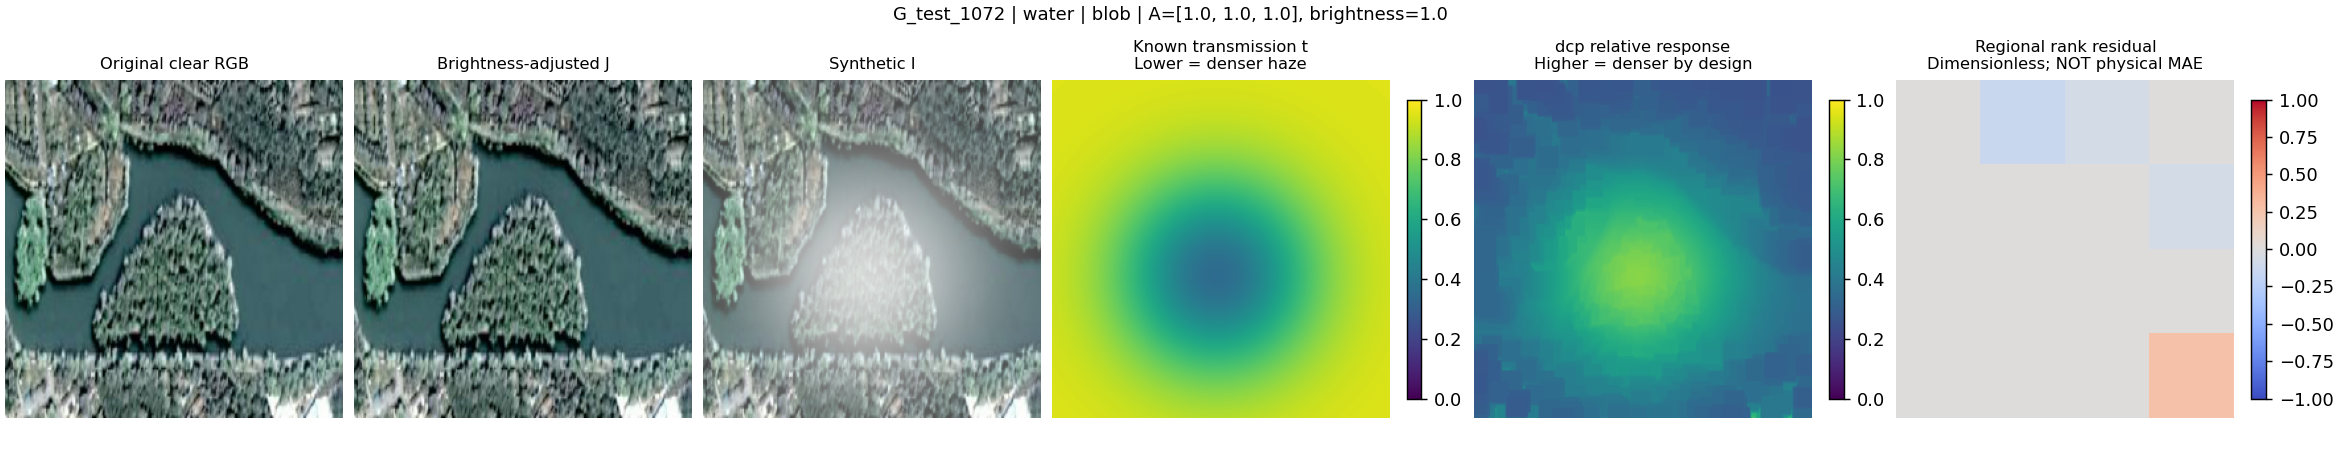

完整 CSV、逐图结果、真值和固定尺度可视化： /mnt/CrossModal-Defog-OVOD/experiments/spatial_v3_run01/benchmarks/20261025T134327_753304Z


In [10]:
# 可单独重跑本单元查看已生成的结果，不重新计算。
from IPython.display import display, Markdown, Image
if 'BENCHMARK_OUTPUT' not in globals():
    raise RuntimeError('请先运行第 8 节评测单元，或把 BENCHMARK_OUTPUT 指向已有的持久化结果目录。')
status_file = BENCHMARK_OUTPUT / 'run_status.json'
if not status_file.is_file():
    raise FileNotFoundError(f'尚无实验状态记录：{status_file}')
print('各阶段执行状态：', json.loads(status_file.read_text(encoding='utf-8')))
accuracy = BENCHMARK_OUTPUT / 'full_results' / 'report.md'
performance = BENCHMARK_OUTPUT / 'performance' / 'report.md'
for path in (accuracy, performance):
    if path.is_file():
        text = path.read_text(encoding='utf-8')
        display(Markdown(text.split('## 固定尺度可视化')[0]))
for figure in sorted((BENCHMARK_OUTPUT / 'full_results/figures').glob('comparison_*.png'))[:4]:
    display(Image(filename=str(figure)))
print('完整 CSV、逐图结果、真值和固定尺度可视化：', BENCHMARK_OUTPUT)


## 如何重复运行

- **新实验**：按顺序运行第 1—6 节；每次从头训练使用新的 `RUN_NAME`。
- **同一运行时续训**：第 5 节设 `RESUME=True`，增大 `EPOCHS` 后运行，再运行第 6 节。
- **新运行时恢复旧实验**：第 1—4 节使用原 `RUN_NAME` 和原设置，然后按上条续训。持久化磁盘中的配置、划分和 checkpoint 会保留。
- **只看已有权重**：同一运行时直接运行第 6 节；新运行时先运行第 1—4 节，再运行第 6 节。
- **最终测试**：方案确定后运行第 7 节，并保留本次报告和输出目录。
- **独立 Benchmark**：完成第 1、3、4 节后可直接运行第 8 节；已有当前版本 `best.pth` 时自动加入学生网络，否则仍能评测 DCP 和三先验。

更多说明见 [操作指南](guides/haze_density_user_guide.md)、[阶段 1 修复报告](stage_1_bugfix_report.md)和 [Notebook 迁移说明](notebook_update_guide.md)。